Data awal: (4018, 11)
Data setelah cleaning: (4018, 11)

Feature engineering selesai.

Distribusi label:
Cuaca
Hujan Ringan    1535
Berawan         1367
Hujan Lebat     1035
Cerah             81
Name: count, dtype: int64

Fitur yang digunakan:
1. T2M_MAX
2. T2M_MIN
3. T2M
4. RH2M
5. WS2M
6. Cloud_Cover
7. ALLSKY_SFC_SW_DWN
8. QV2M

Data latih : 3214 baris
Data uji   : 804 baris

Model Random Forest berhasil dilatih.

HASIL EVALUASI MODEL
Akurasi pada data uji: 0.5311
Akurasi pada data uji: 53.11%

Laporan Klasifikasi:
              precision    recall  f1-score   support

       Cerah       0.94      0.94      0.94        16
     Berawan       0.61      0.62      0.61       274
Hujan Ringan       0.46      0.51      0.48       307
 Hujan Lebat       0.52      0.41      0.46       207

    accuracy                           0.53       804
   macro avg       0.63      0.62      0.62       804
weighted avg       0.53      0.53      0.53       804



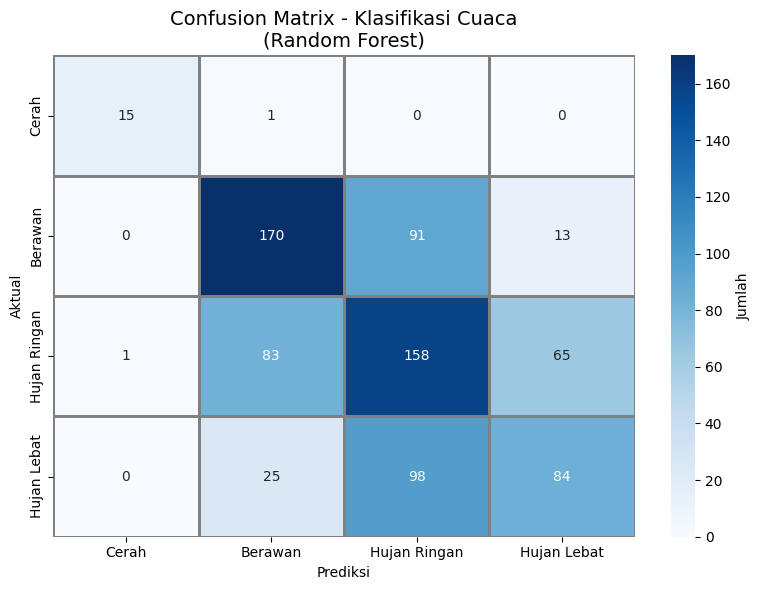


FEATURE IMPORTANCE
            Fitur  Pentingnya
             RH2M    0.210085
          T2M_MAX    0.126961
      Cloud_Cover    0.125650
ALLSKY_SFC_SW_DWN    0.118073
             QV2M    0.117686
          T2M_MIN    0.113157
              T2M    0.109649
             WS2M    0.078738


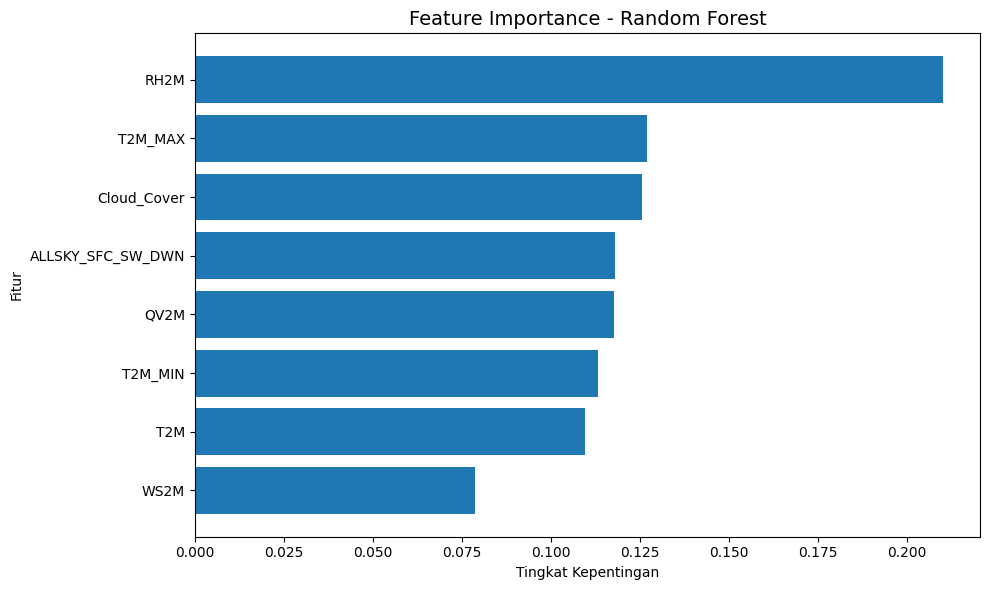


Model berhasil disimpan.

CONTOH PREDIKSI
Prediksi   : Hujan Ringan
Confidence : 84.0%

Probabilitas setiap kelas:
Cerah: 0.0%
Berawan: 6.0%
Hujan Ringan: 84.0%
Hujan Lebat: 10.0%

Label asli : Hujan Ringan


In [28]:
import numpy as np
import pandas as pd
import joblib
import warnings
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

warnings.filterwarnings('ignore')


# ============================================================
# 0. PERSIAPAN FOLDER
# ============================================================

# Karena notebook berada di:
# backend/ml/notebook/training_model.ipynb

DATASET_DIR = '../dataset'
MODEL_DIR = '../model'
IMG_DIR = '../img'

# Membuat folder jika belum ada
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

# ============================================================
# 1. MEMBACA DATA
# ============================================================

file_path = os.path.join(
    DATASET_DIR,
    'nasa_power_pekanbaru_2015_2025.csv'
)

with open(file_path, 'r') as f:
    lines = f.readlines()

start_line = 0

for i, line in enumerate(lines):
    if '-END HEADER-' in line:
        start_line = i + 1
        break

while start_line < len(lines) and lines[start_line].strip() == '':
    start_line += 1

header_line = lines[start_line]

if ';' in header_line:
    sep = ';'
elif ',' in header_line:
    sep = ','
else:
    sep = r'\s+'

df = pd.read_csv(
    file_path,
    sep=sep,
    skiprows=start_line,
    engine='python'
)

print("Data awal:", df.shape)


# ============================================================
# 2. DATA CLEANING
# ============================================================

df.replace(-999, np.nan, inplace=True)

df.dropna(inplace=True)

print("Data setelah cleaning:", df.shape)


# ============================================================
# 3. FEATURE ENGINEERING
# ============================================================

# Menghindari pembagian dengan nilai 0
df['CLRSKY_SFC_SW_DWN'] = df['CLRSKY_SFC_SW_DWN'].replace(
    0, np.nan
)

df.dropna(
    subset=['CLRSKY_SFC_SW_DWN'],
    inplace=True
)

# Menghitung Cloud Cover
df['Cloud_Cover'] = (
    1 -
    (
        df['ALLSKY_SFC_SW_DWN']
        /
        df['CLRSKY_SFC_SW_DWN']
    )
)

# Membatasi nilai antara 0 dan 1
df['Cloud_Cover'] = df['Cloud_Cover'].clip(0, 1)

print("\nFeature engineering selesai.")


# ============================================================
# 4. MEMBUAT LABEL CUACA
# ============================================================

def tentukan_label(row):

    if row['PRECTOTCORR'] >= 10:
        return 'Hujan Lebat'

    elif row['PRECTOTCORR'] >= 2:
        return 'Hujan Ringan'

    elif row['Cloud_Cover'] > 0.5 or row['RH2M'] > 85:
        return 'Berawan'

    else:
        return 'Cerah'


df['Cuaca'] = df.apply(
    tentukan_label,
    axis=1
)

print("\nDistribusi label:")
print(df['Cuaca'].value_counts())


# ============================================================
# 5. KONVERSI LABEL MENJADI ANGKA
# ============================================================

label_map = {
    'Cerah': 0,
    'Berawan': 1,
    'Hujan Ringan': 2,
    'Hujan Lebat': 3
}

df['Label'] = df['Cuaca'].map(label_map)


# ============================================================
# 6. MEMILIH FITUR
# ============================================================

# PRECTOTCORR TIDAK DIGUNAKAN SEBAGAI FITUR
feature_columns = [

    'T2M_MAX',
    'T2M_MIN',
    'T2M',
    'RH2M',
    'WS2M',
    'Cloud_Cover',
    'ALLSKY_SFC_SW_DWN',
    'QV2M'
]

X = df[feature_columns]
y = df['Label']

print("\nFitur yang digunakan:")
for i, feature in enumerate(feature_columns, start=1):
    print(f"{i}. {feature}")


# ============================================================
# 7. SPLIT DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(
    f"\nData latih : {X_train.shape[0]} baris"
)

print(
    f"Data uji   : {X_test.shape[0]} baris"
)


# ============================================================
# 8. PELATIHAN RANDOM FOREST
# ============================================================

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train,
    y_train
)

print("\nModel Random Forest berhasil dilatih.")


# ============================================================
# 9. EVALUASI MODEL
# ============================================================

y_pred = rf.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n========================================")
print("HASIL EVALUASI MODEL")
print("========================================")

print(
    f"Akurasi pada data uji: {accuracy:.4f}"
)

print(
    f"Akurasi pada data uji: {accuracy * 100:.2f}%"
)


# Classification Report
print("\nLaporan Klasifikasi:")

class_names = [
    'Cerah',
    'Berawan',
    'Hujan Ringan',
    'Hujan Lebat'
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

# ============================================================
# 11. VISUALISASI CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=1,
    linecolor='gray',
    cbar_kws={'label': 'Jumlah'}
)

plt.title(
    'Confusion Matrix - Klasifikasi Cuaca\n(Random Forest)',
    fontsize=14
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')

plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, 'confusion_matrix_cuaca.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 12. FEATURE IMPORTANCE
# ============================================================

importances = pd.DataFrame({
    'Fitur': feature_columns,
    'Pentingnya': rf.feature_importances_
}).sort_values(
    'Pentingnya',
    ascending=False
)

print("\n========================================")
print("FEATURE IMPORTANCE")
print("========================================")

print(importances.to_string(index=False))


# ============================================================
# 13. VISUALISASI FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    importances['Fitur'],
    importances['Pentingnya']
)

plt.gca().invert_yaxis()

plt.title(
    'Feature Importance - Random Forest',
    fontsize=14
)

plt.xlabel('Tingkat Kepentingan')
plt.ylabel('Fitur')

plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, 'feature_importance_cuaca.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# 14. SIMPAN MODEL
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    'model_cuaca_randomforest.pkl'
)

joblib.dump(
    rf,
    model_path
)

print("\nModel berhasil disimpan.")

# ============================================================
# 15. FUNGSI PREDIKSI
# ============================================================

def prediksi_cuaca(
    t2m_max,
    t2m_min,
    t2m,
    rh2m,
    ws2m,
    cloud_cover,
    allsky_sw,
    qv2m
):

    input_data = np.array([[
        t2m_max,
        t2m_min,
        t2m,
        rh2m,
        ws2m,
        cloud_cover,
        allsky_sw,
        qv2m
    ]])

    # Prediksi kelas
    pred = rf.predict(input_data)[0]

    # Probabilitas setiap kelas
    probabilities = rf.predict_proba(input_data)[0]

    label_reverse = {
        0: 'Cerah',
        1: 'Berawan',
        2: 'Hujan Ringan',
        3: 'Hujan Lebat'
    }

    # Confidence = probabilitas kelas yang diprediksi
    confidence = probabilities[pred]

    # Probabilitas semua kelas
    probabilitas_kelas = {
        label_reverse[i]: round(float(probabilities[i]) * 100, 2)
        for i in range(len(probabilities))
    }

    return {
        'prediksi': label_reverse[pred],
        'confidence': round(float(confidence) * 100, 2),
        'probabilitas': probabilitas_kelas
    }


# ============================================================
# 16. CONTOH PREDIKSI
# ============================================================

sample = df.iloc[0]

hasil = prediksi_cuaca(

    sample['T2M_MAX'],
    sample['T2M_MIN'],
    sample['T2M'],
    sample['RH2M'],
    sample['WS2M'],
    sample['Cloud_Cover'],
    sample['ALLSKY_SFC_SW_DWN'],
    sample['QV2M']
)

print("\n========================================")
print("CONTOH PREDIKSI")
print("========================================")

print(
    f"Prediksi   : {hasil['prediksi']}"
)

print(
    f"Confidence : {hasil['confidence']}%"
)

print("\nProbabilitas setiap kelas:")

for label, probability in hasil['probabilitas'].items():
    print(
        f"{label}: {probability}%"
    )

print(
    f"\nLabel asli : {sample['Cuaca']}"
)